In [39]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('sales_data.csv')

In [3]:
df.head(2)

,OrderID,OrderDate,CustomerID,CustomerName,Gender,Age,City,State,Region,Segment,...,CostPrice,SellingPrice,DiscountPercent,Sales,Profit,ProfitMarginPercent,PaymentMode,Salesperson,ShippingMode,DeliveryDays
0,O000001,2024-04-06,C00749,Bimala Jani,Male,50,Bally,Telangana,South,Consumer,...,42859,50633.03,20,283544.97,-16468.03,-5.81,Net Banking,Geetika,Express,2
1,O000002,2024-08-16,C01292,Vasana Bala,Male,54,Kalyan-Dombivli,Goa,West,Consumer,...,4073,6873.00,0,48111.00,19600.00,40.74,UPI,Faqid,Same Day,3


In [5]:
df.describe()

,Age,Quantity,CostPrice,SellingPrice,DiscountPercent,Sales,Profit,ProfitMarginPercent,DeliveryDays
count,50000.0000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000
mean,41.5114,4.514200,25112.044300,37075.845342,10.003300,150320.446716,37221.147416,22.988339,5.49248
std,13.8001,2.290586,14419.611008,21988.482630,7.074001,126359.988455,42269.421745,11.749846,2.86250
min,18.0000,1.000000,200.000000,253.390000,0.000000,227.600000,-25796.420000,-8.690000,1.00000
25%,30.0000,3.000000,12615.750000,18329.445000,5.000000,48326.967500,7361.660000,14.810000,3.00000
50%,41.0000,5.000000,25077.500000,36478.025000,10.000000,115105.905000,22315.820000,24.260000,5.00000
75%,53.0000,7.000000,37645.250000,54651.927500,15.000000,222796.635000,52545.977500,32.120000,8.00000
max,65.0000,8.000000,50000.000000,89959.630000,20.000000,707124.800000,310176.400000,44.440000,10.00000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   OrderID              50000 non-null  object 
 1   OrderDate            50000 non-null  object 
 2   CustomerID           50000 non-null  object 
 3   CustomerName         50000 non-null  object 
 4   Gender               50000 non-null  object 
 5   Age                  50000 non-null  int64  
 6   City                 50000 non-null  object 
 7   State                50000 non-null  object 
 8   Region               50000 non-null  object 
 9   Segment              50000 non-null  object 
 10  ProductID            50000 non-null  object 
 11  ProductName          50000 non-null  object 
 12  Category             50000 non-null  object 
 13  SubCategory          50000 non-null  object 
 14  Quantity             50000 non-null  int64  
 15  CostPrice            50000 non-null 

In [7]:
df.isnull().sum()

OrderID                0
OrderDate              0
CustomerID             0
CustomerName           0
Gender                 0
Age                    0
City                   0
State                  0
Region                 0
Segment                0
ProductID              0
ProductName            0
Category               0
SubCategory            0
Quantity               0
CostPrice              0
SellingPrice           0
DiscountPercent        0
Sales                  0
Profit                 0
ProfitMarginPercent    0
PaymentMode            0
Salesperson            0
ShippingMode           0
DeliveryDays           0
dtype: int64

In [8]:
df[df.duplicated()]

,OrderID,OrderDate,CustomerID,CustomerName,Gender,Age,City,State,Region,Segment,...,CostPrice,SellingPrice,DiscountPercent,Sales,Profit,ProfitMarginPercent,PaymentMode,Salesperson,ShippingMode,DeliveryDays


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   OrderID              50000 non-null  object 
 1   OrderDate            50000 non-null  object 
 2   CustomerID           50000 non-null  object 
 3   CustomerName         50000 non-null  object 
 4   Gender               50000 non-null  object 
 5   Age                  50000 non-null  int64  
 6   City                 50000 non-null  object 
 7   State                50000 non-null  object 
 8   Region               50000 non-null  object 
 9   Segment              50000 non-null  object 
 10  ProductID            50000 non-null  object 
 11  ProductName          50000 non-null  object 
 12  Category             50000 non-null  object 
 13  SubCategory          50000 non-null  object 
 14  Quantity             50000 non-null  int64  
 15  CostPrice            50000 non-null 

## 5. Detect Outliers


<!-- 5.Detect outliers  -->


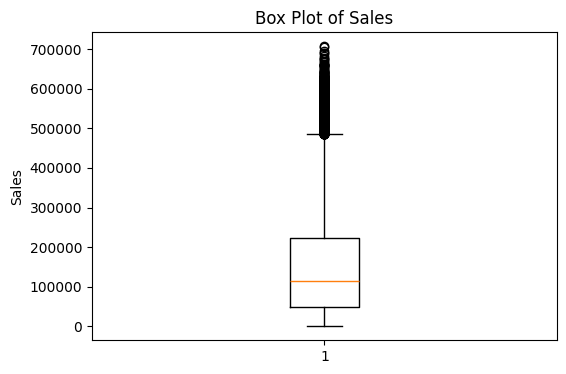

In [29]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Sales'])
plt.title("Box Plot of Sales")
plt.ylabel("Sales")
plt.show()

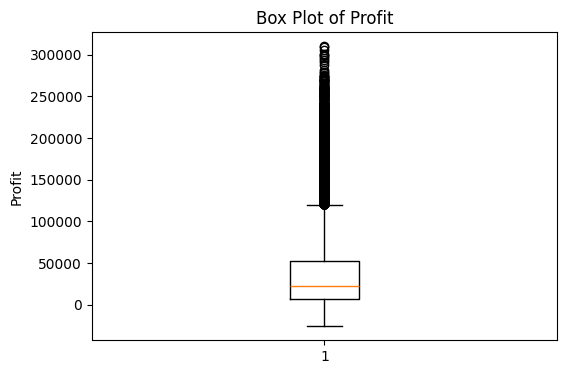

In [31]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Profit'])
plt.title('Box Plot of Profit')
plt.ylabel("Profit")
plt.show()

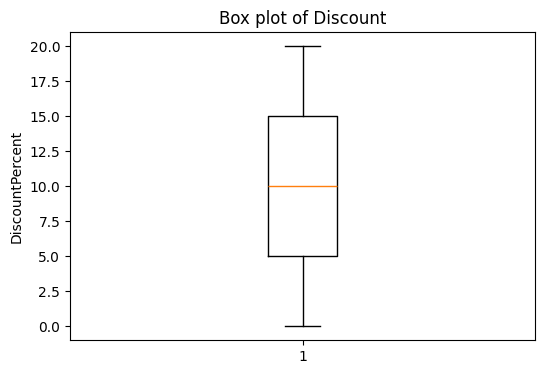

In [32]:
plt.figure(figsize=(6,4))
plt.boxplot(df['DiscountPercent'])
plt.title('Box plot of Discount')
plt.ylabel('DiscountPercent')
plt.show()


## 1.Monthly Sales Trend 

In [61]:
df['OrderDateMonth'] = pd.to_datetime(df['OrderDate'])

In [65]:
df['Month'] = df['OrderDateMonth'].dt.month_name()
df['Month_no'] = df['OrderDateMonth'].dt.month

In [66]:
gb = df.groupby(['Month_no','Month'])['Sales'].sum().reset_index()

In [67]:
gb = gb.sort_values('Month_no')

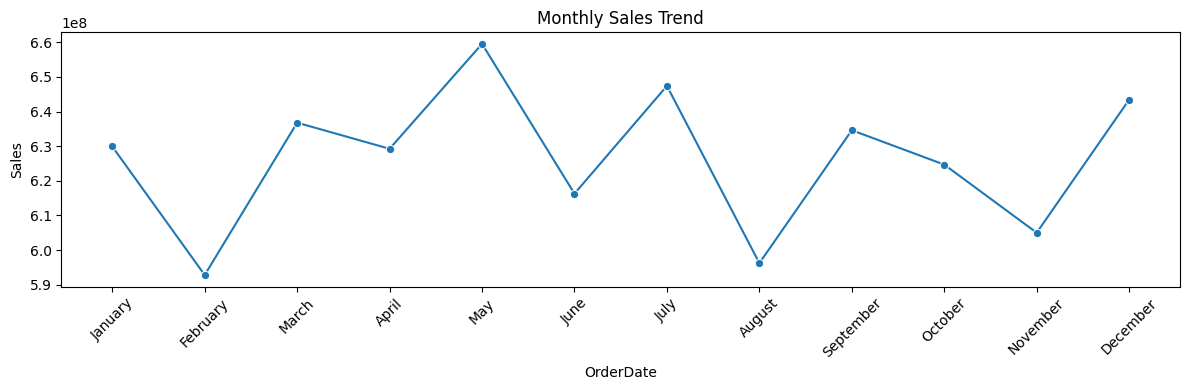

In [68]:
plt.figure(figsize=(12,4))
sns.lineplot(data=gb,x='Month',y='Sales',marker='o')
plt.title('Monthly Sales Trend')
plt.ylabel('Sales')
plt.xlabel('OrderDate')
plt.xticks(rotation=45)
# plt.grid(alpha=0.3,linestyle='--')
plt.tight_layout()
plt.show()

## 2.Monthly Sales Trend 

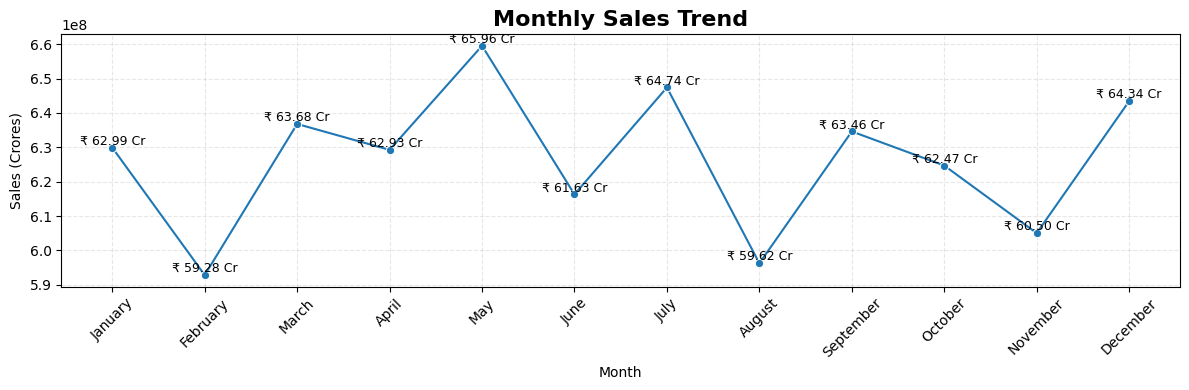

In [69]:
plt.figure(figsize=(12,4))

sns.lineplot(
    data=gb,
    x='Month',
    y='Sales',
    marker='o'
)

for x, y in zip(gb['Month'], gb['Sales']):
    plt.text(
        x,
        y,
        f'₹ {y/10000000:.2f} Cr',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title('Monthly Sales Trend', fontsize=16, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Sales (Crores)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

## Profit Trend 

In [70]:
gb = df.groupby(['Month_no','Month'])['Profit'].sum().reset_index() 

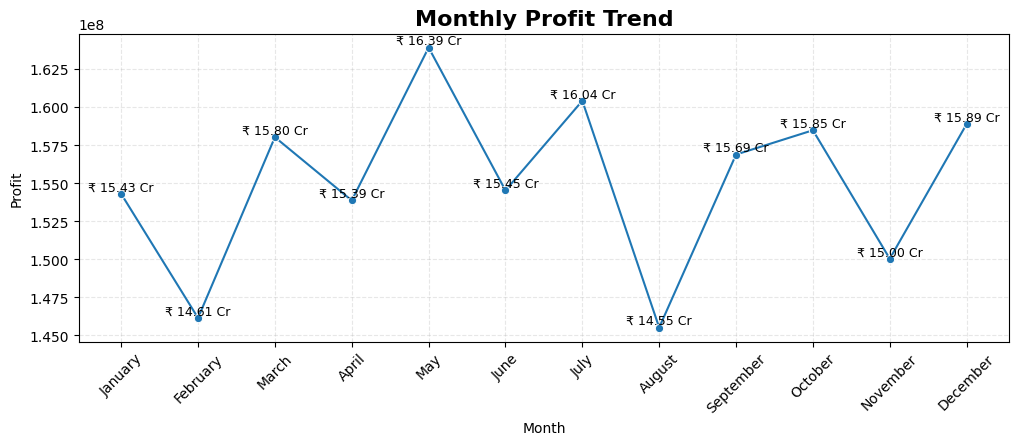

In [78]:
plt.figure(figsize=(12,4)) 
sns.lineplot(data=gb,x='Month',y='Profit',marker='o')

for x,y in zip(gb['Month'],gb['Profit']): 
    plt.text(x,y,f'₹ {y/10000000:.2f} Cr',ha="center",va="bottom",fontsize=9) 

plt.title('Monthly Profit Trend', fontsize=16, fontweight='bold')
plt.ylabel('Profit') 
plt.xlabel('Month') 
plt.xticks(rotation=45)
plt.grid(alpha=0.3,linestyle='--')
plt.show()

## 3.Category Distribution 

In [89]:
gb_category = df.groupby('Category')['Sales'].sum().reset_index()

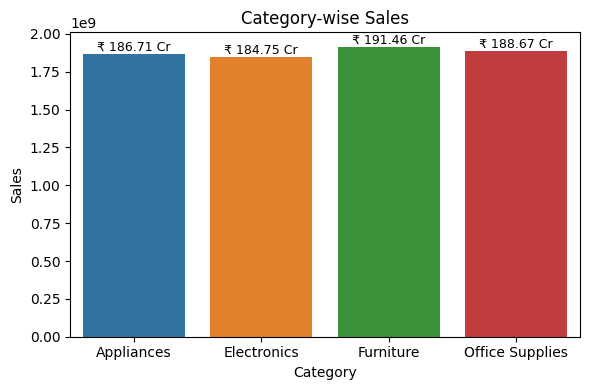

In [95]:
plt.figure(figsize=(6,4))

ax = sns.barplot(data=gb_category, x='Category', y='Sales')

for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'₹ {height/10000000:.2f} Cr',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title("Category-wise Sales")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 4.Sales by Region 

In [96]:
gb_region = df.groupby('Region')['Sales'].sum().reset_index()

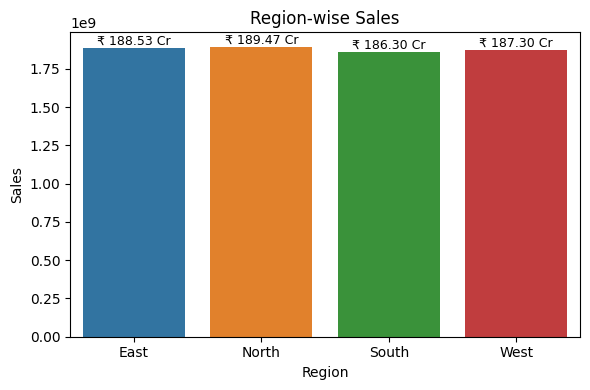

In [98]:
plt.figure(figsize=(6,4))

ax = sns.barplot(data=gb_region, x='Region', y='Sales')

for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'₹ {height/10000000:.2f} Cr',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title("Region-wise Sales")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## Top Products

In [109]:
gb_top_product = df.groupby('ProductName')['Sales'].sum().reset_index().sort_values(by='Sales',ascending=False).head(10)

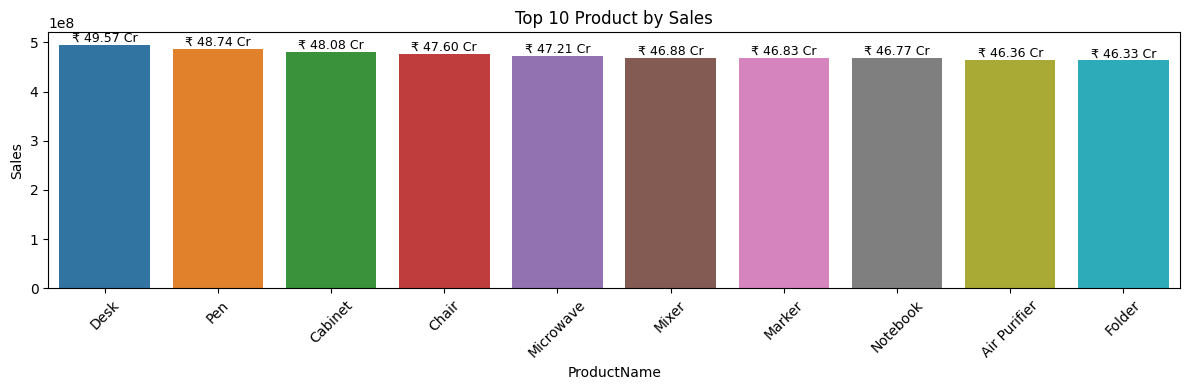

In [113]:
plt.figure(figsize=(12,4))

ax = sns.barplot(data=gb_top_product, x='ProductName', y='Sales')

for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'₹ {height/10000000:.2f} Cr',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title("Top 10 Product by Sales")
plt.xlabel("ProductName")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6.Top Customers 

In [111]:
gb_cus = df.groupby('CustomerName')['Profit'].sum().reset_index().sort_values(by='Profit', ascending=False).head(10)

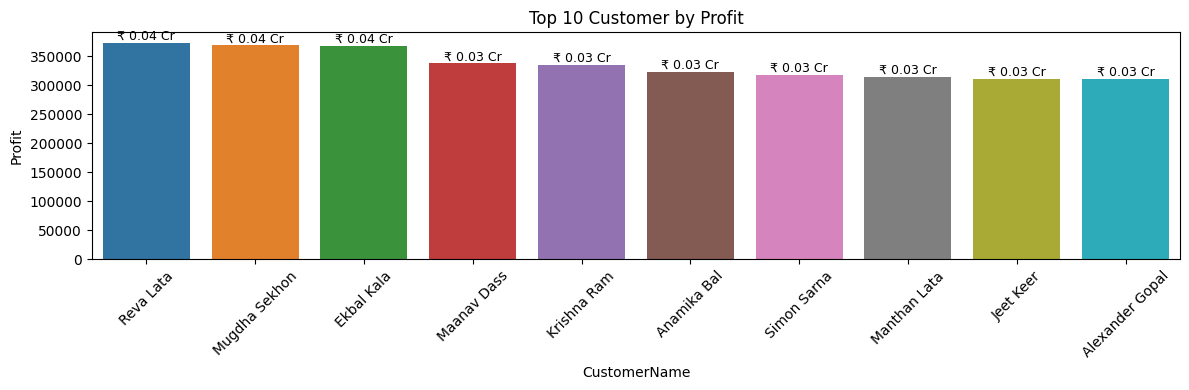

In [112]:
plt.figure(figsize=(12,4))

ax = sns.barplot(data=gb_cus, x='CustomerName', y='Profit')

for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'₹ {height/10000000:.2f} Cr',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.title("Top 10 Customer by Profit")
plt.xlabel("CustomerName")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7.Payment Mode Analysis 

In [142]:
gb_py = df.groupby('PaymentMode')['CustomerID'].count().reset_index().sort_values(by="CustomerID",ascending=False)

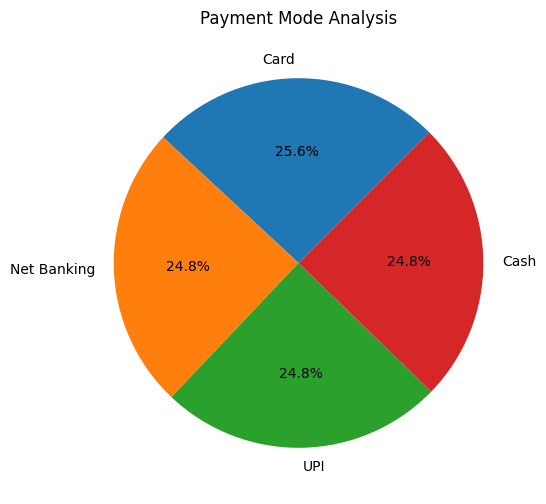

In [143]:
plt.figure(figsize=(6,6))

plt.pie(
    gb_py['CustomerID'],
    labels=gb_py['PaymentMode'],
    autopct='%1.1f%%',
    startangle=45
)

plt.title("Payment Mode Analysis")
plt.show()

# #8.Shipping Mode Analysis 

In [133]:
gb_sp = df.groupby('ShippingMode')['CustomerID'].count().reset_index().sort_values(by="CustomerID",ascending=False)

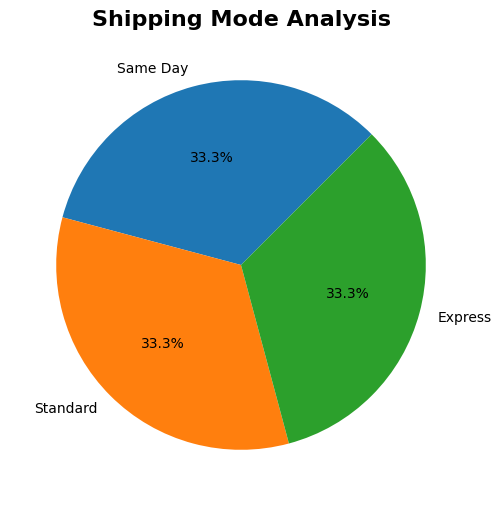

In [139]:
plt.figure(figsize=(6,6))
plt.pie(
    gb_sp['CustomerID'],labels=gb_sp['ShippingMode'], 
    autopct='%1.1f%%' ,
    startangle=45
)
plt.title("Shipping Mode Analysis",fontsize=16,fontweight='bold')
plt.show()

## Correlation Heatmap 

In [146]:
num_df = df.select_dtypes(include='number')

In [151]:
corr = num_df.corr()

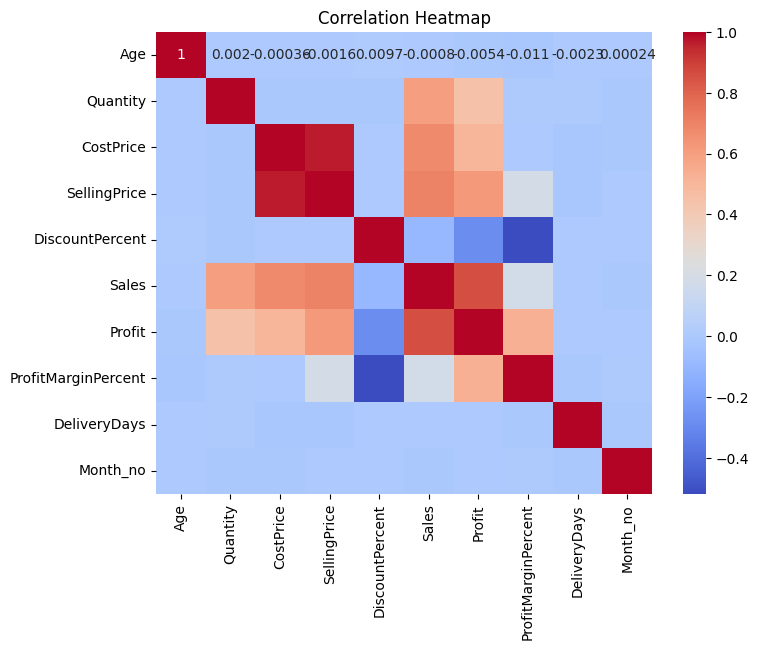

In [149]:
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

## 10.Box Plot for Sales 

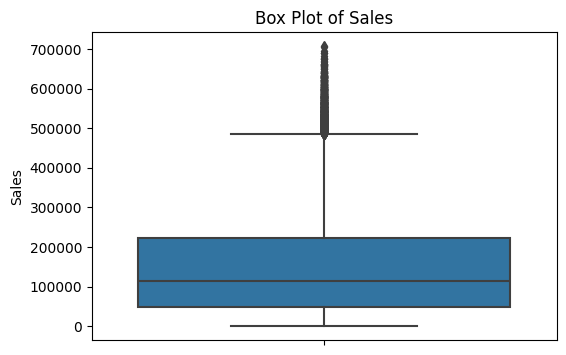

In [152]:
plt.figure(figsize=(6,4))
sns.boxplot(y=df['Sales'])

plt.title("Box Plot of Sales")
plt.ylabel("Sales")

plt.show()